# 10 — Off-policy n-step SARSA Prediction

고정 Target Policy의 Qπ를 추정하는 **Policy Evaluation** 예제다. 새로운 Learner 없이 기존 조합 함수를 재사용한다. 환경·Window·학습 순서를 직접 작성하고 수학적 Return은 examples 구현을 호출한다.

### 실행 설정
`MODULARRL_FAST=1`은 CI용 FAST, 기본값은 FULL입니다. 각 Notebook은 독립 Kernel에서 실행합니다. 처음부터 Run All하면 RNG·Model·학습 상태를 다시 만듭니다.

In [1]:
from pathlib import Path
import os, sys, json
root = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'pyproject.toml').exists())
if str(root) not in sys.path: sys.path.insert(0, str(root))
import gymnasium as gym
import numpy as np
import torch
from torch import nn
import matplotlib.pyplot as plt
from copy import deepcopy
from collections import deque
from modular_rl.model import Model
from modular_rl.component.representation import IdentityRepresentation, MLPRepresentation
from modular_rl.component.estimator import TabularVEstimator, TabularQEstimator, DiscreteQEstimator
from modular_rl.component.action_selector import EpsilonGreedyActionSelector
from modular_rl.component.target_generator import TD0TargetGenerator, MonteCarloReturnGenerator, NStepTargetGenerator
from modular_rl.component.update_rule import TabularVUpdateRule, TabularQUpdateRule, TDLossUpdateRule
from modular_rl.component.buffer import ReplayBuffer, SequenceReplayBuffer
from modular_rl.data import Transition, Episode
from modular_rl.learner import (TabularQLearner, TabularSARSALearner, TabularTD0PredictionLearner,
    MCPredictionLearner, TabularMCControlLearner, OffPolicyMCPredictionLearner, OffPolicyMCControlLearner, DQNLearner)
from modular_rl.dp import policy_evaluation, policy_iteration, value_iteration, uniform_policy, action_values
from notebooks.gymnasium.tutorial_utils import (frozenlake_mdp, evaluate, history, record, frozen_report, neural_report)
FAST = os.environ.get('MODULARRL_FAST', '0') == '1'  # 기본 FULL, CI는 FAST=1
SEED = 7
GAMMA = .99
np_rng = np.random.default_rng(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(1)
plt.close('all')
print({'mode': 'FAST' if FAST else 'FULL', 'seed': SEED, 'gamma': GAMMA, 'device': 'cpu'})

{'mode': 'FAST', 'seed': 7, 'gamma': 0.99, 'device': 'cpu'}


In [2]:
env = gym.make('FrozenLake-v1', map_name='4x4', is_slippery=False, max_episode_steps=1000)
eval_env = gym.make('FrozenLake-v1', map_name='4x4', is_slippery=False, max_episode_steps=100)
S, A = int(env.observation_space.n), int(env.action_space.n)
print(env.observation_space, env.action_space)
desc = env.unwrapped.desc.copy()

Discrete(16) Discrete(4)


In [3]:
representation = IdentityRepresentation()  # 정수 State Index를 유지한다.
estimator = TabularQEstimator(S, A)
selector = EpsilonGreedyActionSelector(1.)
model = Model(representation, estimator, selector).double()
target_generator = TD0TargetGenerator(GAMMA)
update_rule = TabularQUpdateRule(.5)
from examples.gridworld_off_policy_n_step_sarsa import learn_off_policy_n_step_sarsa
selector.epsilon = 1.
update_rule = TabularQUpdateRule(.05)
target_policy = torch.tensor([[.3,.2,.2,.3]]*S, dtype=torch.float64)
mdp = frozenlake_mdp(env)
N = 3
log = history()

### 정책과 Return의 범위
고정 Target π를 평가한다. Behavior는 Uniform ε=1이며 Target은 [.3,.2,.2,.3]이다.
Behavior log_prob은 수집 당시 값이고, Coverage는 호출자 책임이다. Control 알고리즘이라고 소개하지 않는다.

In [4]:
for episode_index in range(60 if FAST else 3000):
    observation, _ = env.reset(seed=SEED if episode_index == 0 else None)
    selected = model.act(observation)
    pending = deque()

    total, length = 0., 0
    while True:
        next_observation, reward, terminated, truncated, _ = env.step(selected.action.item())
        reward = float(reward)  # 학습 reward의 floating 계약
        next_selected = None if terminated else model.act(next_observation)
        next_action = None if next_selected is None else next_selected.action
        next_log = None if next_selected is None else next_selected.log_prob.detach().clone()
        pending.append(Transition(observation, selected.action, reward, next_observation, terminated, truncated, selected.log_prob).to_batch())

        if len(pending) == N:
            result = learn_off_policy_n_step_sarsa(model, pending, target_generator, update_rule,
                    target_policy=target_policy, bootstrap_action=next_action, bootstrap_log_prob=next_log)
            pending.popleft()

        total += reward; length += 1
        if terminated or truncated:
            while pending:
                result = learn_off_policy_n_step_sarsa(model, pending, target_generator, update_rule,
                    target_policy=target_policy, bootstrap_action=next_action, bootstrap_log_prob=next_log)
                pending.popleft()

            break
        observation = next_observation
        selected = next_selected
    record(log, total, length, terminated, truncated)
reference = policy_evaluation(mdp, target_policy.numpy(), gamma=GAMMA).values
q_reference = action_values(mdp, reference, GAMMA)
nonterminal = [s for s in range(S) if s not in mdp.terminal_states]
print('fixed-target Qpi RMSE', float(np.sqrt(np.mean((model.estimator.q_table.numpy()[nonterminal]-q_reference[nonterminal])**2))))

fixed-target Qpi RMSE 0.15019024104652812


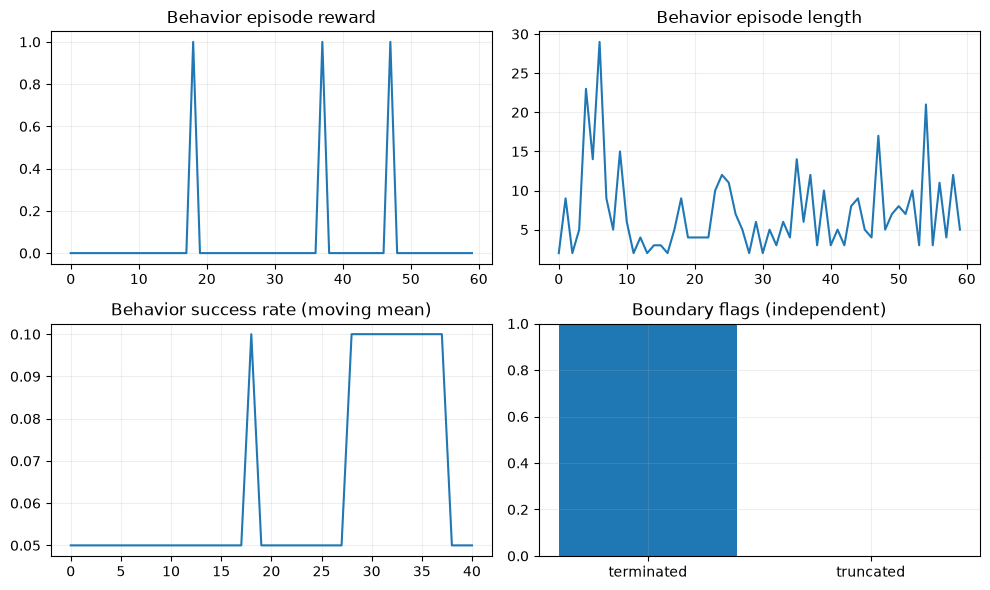

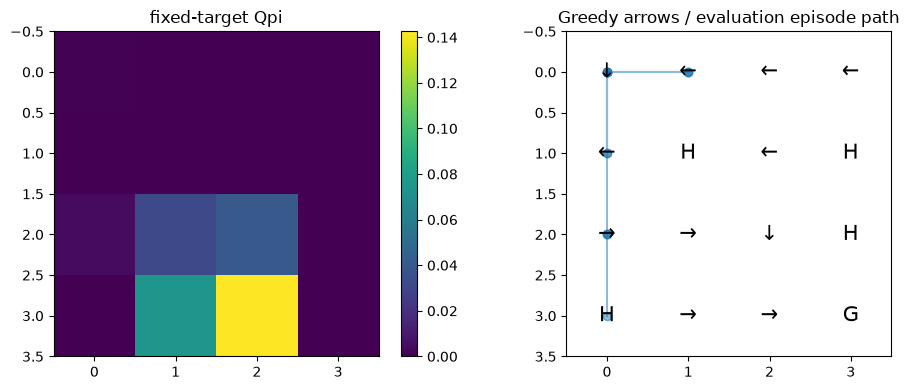

fixed-target Qpi [[0.     0.0008 0.     0.    ]
 [0.     0.     0.     0.    ]
 [0.     0.     0.     0.    ]
 [0.     0.     0.     0.    ]
 [0.0005 0.     0.     0.    ]
 [0.     0.     0.     0.    ]
 [0.     0.     0.     0.    ]
 [0.     0.     0.     0.    ]
 [0.001  0.     0.0043 0.    ]
 [0.     0.0282 0.0317 0.    ]
 [0.     0.0396 0.     0.    ]
 [0.     0.     0.     0.    ]
 [0.     0.     0.     0.    ]
 [0.     0.0314 0.075  0.    ]
 [0.     0.     0.1426 0.    ]
 [0.     0.     0.     0.    ]]
RESULT {"environment_steps": 433, "episodes": 60, "evaluation_mean_reward": 0.0, "evaluation_success": 0.0, "terminated_rate": 1.0, "truncated_rate": 0.0}


In [5]:
model.eval()
evaluation = evaluate(eval_env, lambda state: np_rng.choice(A, p=target_policy[state].numpy()), episodes=5 if FAST else 100, seed=SEED+1000)
table = model.estimator.q_table.detach().cpu().numpy()
greedy_actions = table.argmax(-1)
summary = frozen_report(desc, log, table, evaluation, greedy_actions=greedy_actions, label='fixed-target Qpi')
env.close(); eval_env.close()

### 이번 조합에서 드러난 API 특성
고정 정책과 Behavior 확률, 시간순 Window를 호출자가 전달한다. 마지막 Bootstrap 평가와 행동 선택 순서는 알고리즘마다 다르다. 이 기능은 examples 지원이며 범용 SequenceReplay로 대체하지 않는다.

### API 사용성 기록 — 아래 빈칸을 직접 수정해 보세요

|질문|실행 후 관찰/개선 제안|
|---|---|
|Model 생성이 자연스러운가?| |
|Learner 구성은 직관적인가?| |
|TargetGenerator를 선택하기 쉬운가?| |
|Buffer의 사용법이 일관적인가?| |
|Experience 자료형을 직접 조작할 필요가 있는가?| |
|학습 호출이 간결한가?| |
|Algorithm-specific 코드가 얼마나 필요한가?| |
|불필요한 자료형 변환이 존재하는가?| |
|API만 보고 학습 과정이 이해되는가?| |
|공용 컴포넌트로 옮길 필요가 있는 코드가 있는가?| |

FAST는 연결과 Shape 검사용이며 성능 판정이 아니다. FULL은 실제 학습용이다.
Seed 하나의 성공률로 알고리즘의 정확성을 판단하지 않는다. `terminated`와 `truncated`는
독립적인 flag이며 실제 마지막 관측을 저장한다. 아래 helper는 시각화·평가만 담당하고 학습을 숨기지 않는다.